## Правила
 Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).
 Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.
 Поддерживаются операции пополнения и снятия:

Сумма операции должна быть положительной.
Некорректная сумма приводит к исключению.
При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.
Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.
 Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.
 Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.




                                     ВЫПИСКА ПО СЧЁТУ                                     
                                     Владелец: Пупкин                                     
                                  Номер счёта: ACC-1000                                   
                                   Текущий баланс: 0 ₽                                    
Дата                  Тип                Сумма  Статус                              Баланс
------------------------------------------------------------------------------------------
2026-10-29 21:36:46   Пополнение       1000.00  ✓ Операция прошла успешно          1000.00
2026-10-29 21:36:47   Снятие            300.00  ✓ Операция прошла успешно           700.00
2026-10-29 21:36:48   Снятие            200.00  ✓ Операция прошла успешно           500.00
2026-10-29 21:36:49   Снятие            500.00  ✓ Операция прошла успешно             0.00
-----------------------------------------------------------------------------------------

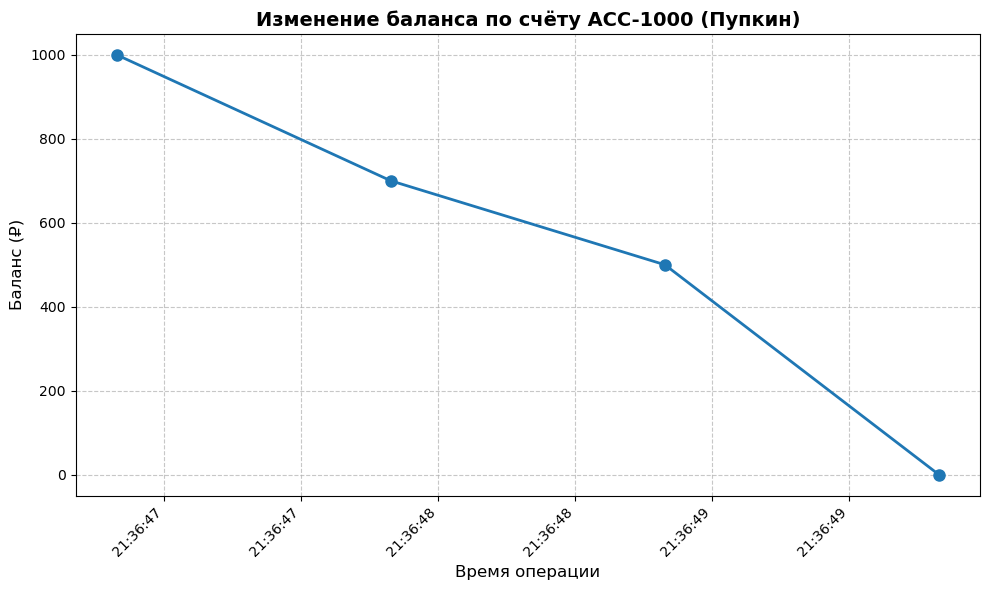

In [44]:
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

class Account:
    next_account_number = 1000

    def __init__(self, owner, initial_balance=0):
        self.owner = owner
        self.balance = initial_balance
        self.history = []
        self.account_number = f"ACC-{type(self).next_account_number:04d}"
        type(self).next_account_number += 1

    def _add_history_record(self, operation_type, amount, status):
        """Вспомогательный метод для добавления записи в историю"""
        self.history.append({
            'type': operation_type,
            'amount': amount,
            'date': datetime.now(),
            'balance_after': self.balance,
            'status': status,
        })

    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Сумма пополнения должна быть положительной")
        self.balance += amount
        self._add_history_record('deposit', amount, 'Операция прошла успешно')

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError("Сумма снятия должна быть положительной")
        if amount > self.balance:
            self._add_history_record('withdraw', amount, 'Отказано')
            return False
        self.balance -= amount
        self._add_history_record('withdraw', amount, 'Операция прошла успешно')
        return True

    def get_balance(self):
        return self.balance

    def get_history(self):
        return self.history

    def print_history(self):
        """Красивый вывод истории операций"""
        w_date, w_type, w_sum, w_status, w_bal = 20, 12, 10, 30, 10
        sep = "  "
        width = w_date + w_type + w_sum + w_status + w_bal + len(sep) * 4

        print("\n" + "=" * width)
        print(f"{'ВЫПИСКА ПО СЧЁТУ':^{width}}")
        print(f"{'Владелец: ' + self.owner:^{width}}")
        print(f"{'Номер счёта: ' + self.account_number:^{width}}")
        print(f"{'Текущий баланс: ' + str(self.balance) + ' ₽':^{width}}")
        print("=" * width)

        if not self.history:
            print("Операции отсутствуют")
            print("=" * width + "\n")
            return

        print(f"{'Дата':<{w_date}}{sep}"
              f"{'Тип':<{w_type}}{sep}"
              f"{'Сумма':>{w_sum}}{sep}"
              f"{'Статус':<{w_status}}{sep}"
              f"{'Баланс':>{w_bal}}")
        print("-" * width)

        for record in self.history:
            date_str = record['date'].strftime('%Y-%m-%d %H:%M:%S')
            operation = "Пополнение" if record['type'] == 'deposit' else "Снятие"
            is_success = record['status'] == 'Операция прошла успешно'
            status_icon = "✓" if is_success else "✗"
            status_text = f"{status_icon} {record['status']}"

            print(f"{date_str:<{w_date}}{sep}"
                  f"{operation:<{w_type}}{sep}"
                  f"{record['amount']:>{w_sum}.2f}{sep}"
                  f"{status_text:<{w_status}}{sep}"
                  f"{record['balance_after']:>{w_bal}.2f}")

        print("-" * width)
        print(f"Всего операций: {len(self.history)}")
        print("=" * width + "\n")

    def plot_balance_history(self):
        """Построение линейного графика изменения баланса во времени"""
        if not self.history:
            print("Недостаточно данных для построения графика.")
            return
        
        # Извлекаем данные для осей
        dates = [record['date'] for record in self.history]
        balances = [record['balance_after'] for record in self.history]
        
        # Настройка шрифтов для корректного отображения кириллицы
        plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']
        plt.rcParams['axes.unicode_minus'] = False
        
        # Создание фигуры
        plt.figure(figsize=(10, 6))
        
        # Построение линейного графика с маркерами
        plt.plot(dates, balances, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=8)
        
        # Форматирование оси X (время) для лучшей читаемости
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
        plt.gcf().autofmt_xdate(rotation=45)
        
        # Заголовок и подписи осей
        plt.title(f"Изменение баланса по счёту {self.account_number} ({self.owner})", fontsize=14, fontweight='bold')
        plt.xlabel("Время операции", fontsize=12)
        plt.ylabel("Баланс (₽)", fontsize=12)
        
        # Сетка и оформление
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        
        # Отображение графика
        plt.show()


# ==============================
# Тестирование Этапа 2
# ==============================
if __name__ == "__main__":
    user = Account("Пупкин")
    
    # Генерируем историю операций с небольшими паузами для наглядности на графике
    user.deposit(1000)
    
    import time
    time.sleep(1)  # Имитация прохождения времени
    
    user.withdraw(300)
    time.sleep(1)
    
    user.withdraw(200)
    time.sleep(1)
    
    user.withdraw(500)  # Эта операция будет "Отказано", баланс не изменится, но точка на графике будет
    
    # Выводим текстовую историю
    user.print_history()
    
    # Строим график
    user.plot_balance_history()